# Phishing Email Analysis using LLMs

## Introduction

This Jupyter notebook demonstrates how to use Large Language Models (LLMs) to analyze emails for potential phishing attempts. We'll use the Ollama framework to run a local LLM, then create a simple GUI for one-shot email analysis. Finally, we will test our process with a realworld datasets of phishing emails.

## Setup

First, we need to install Ollama and set up our environment. The setup is exactly the same that we did in the the previous collab.

In [1]:
# Install missing zstd dependency and run the official installation script
!sudo apt-get update && sudo apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh
!/usr/local/bin/ollama --version

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information...

Next, we'll set up the necessary environment variables and start the Ollama server:

In [2]:
import os
import subprocess
import time
import requests

# Set CUDA/GPU environment paths
os.environ['PATH'] += ':/usr/local/cuda/bin:/usr/local/bin'
os.environ['LD_LIBRARY_PATH'] = '/usr/lib64-nvidia:/usr/local/cuda/lib64'

print("Launching Ollama service in the background...")
# Start Ollama service using nohup to keep it running in the background
subprocess.Popen(["nohup", "/usr/local/bin/ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

# Wait and verify connection
print("Verifying connection to Ollama server at http://127.0.0.1:11434/ ...")
for i in range(15):
    try:
        response = requests.get('http://127.0.0.1:11434/', timeout=2)
        if response.status_code == 200:
            print("Success: Ollama service is fully responsive!")
            break
    except requests.exceptions.ConnectionError:
        time.sleep(2.0)
else:
    print("Warning: Connection timed out. Ollama daemon might still be initializing.")

Launching Ollama service in the background...
Verifying connection to Ollama server at http://127.0.0.1:11434/ ...
Success: Ollama service is fully responsive!


## Install dependencies

Now, let's install the required Python packages that we will need.


In [3]:
# We first need to install dependencies
%pip install openai pydantic instructor ipywidgets beautifulsoup4 pandas tqdm chardet matplotlib seaborn wordcloud

## Download the LLM model

You can use another model available in the [ollama library](https://ollama.com/library)

In [4]:
import os
import subprocess

OLLAMA_MODEL = "gemma2:9b-instruct-q4_K_M"

# Let's verify the binary path directly
possible_paths = ["/usr/local/bin/ollama", "/usr/bin/ollama", "/bin/ollama"]
ollama_path = None

for path in possible_paths:
    if os.path.exists(path):
        ollama_path = path
        break

if not ollama_path:
    # If missing, it's possible the installer failed silently or placed it in another directory.
    # Let's run a quick locate and check /usr/local/bin contents.
    print("Listing /usr/local/bin:", os.listdir('/usr/local/bin') if os.path.exists('/usr/local/bin') else 'Does not exist')
    ollama_path = "ollama" # Fallback to default

print(f"Pulling model '{OLLAMA_MODEL}' using binary: {ollama_path}")
!{ollama_path} pull {OLLAMA_MODEL}

Pulling model 'gemma2:9b-instruct-q4_K_M' using binary: /usr/local/bin/ollama



In [5]:
# Run a direct model pull via the active daemon
!/usr/local/bin/ollama pull gemma2:9b-instruct-q4_K_M

## Define data models

Let's define our Pydantic models for structuring the phishing analysis results:

In [6]:
from pydantic import BaseModel, Field
from enum import Enum
from typing import List

class PhishingProbability(str, Enum):
    LOW = "low"
    MEDIUM = "medium"
    HIGH = "high"

class SuspiciousElement(BaseModel):
    element: str
    reason: str

class SimplePhishingAnalysis(BaseModel):
    is_potential_phishing: bool
    phishing_probability: PhishingProbability
    suspicious_elements: List[SuspiciousElement]
    recommended_actions: List[str]
    explanation: str

## Implement email analysis function

Now, let's create a function to analyze emails using our LLM:

In [7]:
# Ensure instructor and schema requirements are defined in this cell
try:
    import instructor
except ImportError:
    !pip install -q instructor
    import instructor

from pydantic import BaseModel, Field
from enum import Enum
from typing import List
from openai import OpenAI

class PhishingProbability(str, Enum):
    LOW = "low"
    MEDIUM = "medium"
    HIGH = "high"

class SuspiciousElement(BaseModel):
    element: str
    reason: str

class SimplePhishingAnalysis(BaseModel):
    is_potential_phishing: bool
    phishing_probability: PhishingProbability
    suspicious_elements: List[SuspiciousElement]
    recommended_actions: List[str]
    explanation: str

def analyze_email(email_content: str) -> SimplePhishingAnalysis:
    client = instructor.from_openai(
        OpenAI(
            base_url="http://127.0.0.1:11434/v1",
            api_key="ollama",  # required, but unused
        ),
        mode=instructor.Mode.JSON,
    )

    resp = client.chat.completions.create(
        model=OLLAMA_MODEL,
        messages=[
            {
                "role": "system",
                "content": "You are an advanced AI assistant specialized in cybersecurity, particularly in detecting and analyzing phishing attempts in emails. Your task is to analyze the provided email content and metadata to determine if it's a potential phishing attempt. You must provide your analysis in a structured format that matches the model.",
            },
            {
                "role": "user",
                "content": email_content,
            },
        ],
        response_model=SimplePhishingAnalysis,
    )
    return resp

## Test the analysis function

Let's test our analysis function with example emails:

In [8]:
import json
import requests

# Pre-flight check: Ensure Ollama is responsive before proceeding
try:
    response = requests.get('http://127.0.0.1:11434/', timeout=2)
    if response.status_code != 200:
        raise ConnectionError("Ollama responded but is not fully healthy.")
except Exception as e:
    raise ConnectionError(
        "Ollama background server is NOT running. Please run the setup cells (including vTbRV6XgDgWn) to start Ollama before executing this analysis cell."
    ) from e

# Example phishing email
phishing_email = """
From: security@amazonsupport.net
To: john.doe@company.com
Subject: Urgent: Your Amazon Account Has Been Locked

Dear Valued Customer,

We have detected unusual activity on your Amazon account. To prevent unauthorized access, we have temporarily locked your account for your protection.

To unlock your account and restore full access, please click on the link below and verify your information:

https://amaz0n-account-verify.com/unlock-account

If you do not verify your account within 24 hours, it will be permanently disabled.

Thank you for your prompt attention to this matter.

Best regards,
Amazon Security Team

This email was sent by Amazon.com. To ensure delivery to your inbox, please add security@amazonsupport.net to your address book.
"""

analysis = analyze_email(phishing_email)
print(json.dumps(analysis.model_dump(), indent=2))

# Example legitimate email
legitimate_email = """
From: jennifer.smith@company.com
To: team@company.com
Subject: Quarterly Review Meeting - Thursday, 2 PM

Dear Team,

I hope this email finds you well. I'm writing to remind everyone about our upcoming Quarterly Review Meeting scheduled for this Thursday at 2 PM in the main conference room.

Agenda:
1. Q2 Performance Overview
2. Project Updates
3. Q3 Goals and Strategies
4. Open Discussion

Please come prepared with your team's updates and any questions you may have. If you're unable to attend in person, you can join via our usual video conferencing link:
https://company.zoom.us/j/123456789

Don't forget to bring your laptops for the interactive portion of the meeting.

If you have any questions or need to discuss anything before the meeting, feel free to drop by my office or send me an email.

Looking forward to seeing everyone on Thursday!

Best regards,
Jennifer Smith
Head of Operations
Company Inc.
"""

analysis = analyze_email(legitimate_email)
print(json.dumps(analysis.model_dump(), indent=2))

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Sender Email Address",
      "reason": "The sender email address is similar to a legitimate address but contains a slight variation (amazonsupport.net instead of amazonservices.com)."
    },
    {
      "element": "Subject Line",
      "reason": "The subject line uses urgent language ('Urgent: Your Amazon Account Has Been Locked') to pressure the recipient into taking immediate action."
    },
    {
      "element": "Unrealistic Timeframe",
      "reason": "The email demands action within a short, unrealistic timeframe (24 hours)."
    },
    {
      "element": "Generic Greeting",
      "reason": "The email uses a generic greeting ('Dear Valued Customer') instead of addressing the recipient by name."
    },
    {
      "element": "Suspicious Link",
      "reason": "The email contains a link that directs to a domain that is suspicious and likely not affiliated with Ama

In [9]:
import requests

try:
    response = requests.get('http://127.0.0.1:11434/')
    print(f"Status Code: {response.status_code}")
    print(f"Response: {response.text}")
except requests.exceptions.ConnectionError:
    print("Ollama is NOT running. Connection refused.")

Status Code: 200
Response: Ollama is running


## Create a GUI for Email Analysis

Finally, let's create a simple GUI for email analysis using IPython widgets. It will take as input only a text box but you can improve it by using a mailbox parser, supporting attachments, ioc extractions...

In [10]:
from IPython.display import display, HTML
import ipywidgets as widgets

# GUI components
email_input = widgets.Textarea(
    value='',
    placeholder='Paste the email content here...',
    description='Email:',
    disabled=False,
    layout={'width': '100%', 'height': '200px'}
)

analyze_button = widgets.Button(
    description='Analyze Email',
    disabled=False,
    button_style='primary',
    tooltip='Click to analyze the email',
    icon='check'
)

output = widgets.Output()

def on_button_clicked(b):
    with output:
        output.clear_output()
        print("Analyzing email...")
        try:
            analysis = analyze_email(email_input.value)
            display(HTML(format_analysis(analysis)))
        except Exception as e:
            print(f"An error occurred: {str(e)}")

analyze_button.on_click(on_button_clicked)

def format_analysis(analysis: SimplePhishingAnalysis) -> str:
    color = "red" if analysis.is_potential_phishing else "green"
    result = f"""
    <h2 style="color: {color};">{'Potential Phishing Detected' if analysis.is_potential_phishing else 'Likely Legitimate Email'}</h2>
    <p><strong>Phishing Probability:</strong> {analysis.phishing_probability.value}</p>
    <h3>Suspicious Elements:</h3>
    <ul>
    """
    for element in analysis.suspicious_elements:
        result += f"<li><strong>{element.element}:</strong> {element.reason}</li>"
    result += "</ul>"
    result += f"""
    <h3>Recommended Actions:</h3>
    <ul>
    """
    for action in analysis.recommended_actions:
        result += f"<li>{action}</li>"
    result += "</ul>"
    result += f"<h3>Explanation:</h3><p>{analysis.explanation}</p>"
    return result

# Display the GUI
display(email_input, analyze_button, output)

Textarea(value='', description='Email:', layout=Layout(height='200px', width='100%'), placeholder='Paste the e…

Button(button_style='primary', description='Analyze Email', icon='check', style=ButtonStyle(), tooltip='Click …

Output()

### Interactive Phishing Analysis Dashboard
Use this interactive form to paste raw email headers and body content, then run a local evaluation against `gemma2:9b-instruct`.

In [11]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Create visual components
email_textbox = widgets.Textarea(
    value='',
    placeholder='Paste raw email headers and body here...',
    description='Email Source:',
    disabled=False,
    layout=widgets.Layout(width='98%', height='250px')
)

analyze_btn = widgets.Button(
    description='Analyze for Phishing',
    disabled=False,
    button_style='danger',
    tooltip='Send to local Gemma model',
    icon='shield'
)

output_panel = widgets.Output()

def trigger_analysis(button_instance):
    with output_panel:
        output_panel.clear_output()
        email_raw = email_textbox.value.strip()
        if not email_raw:
            print("Please paste an email body to analyze.")
            return

        print("Sending email to local Ollama instance (gemma2)... Please wait...")
        try:
            analysis = analyze_email(email_raw)
            # Render visual results using HTML formatting
            html_report = format_analysis(analysis)
            display(HTML(html_report))
        except Exception as e:
            print(f"Evaluation error: {e}")

analyze_btn.on_click(trigger_analysis)

# Display the widgets
ui_container = widgets.VBox([email_textbox, analyze_btn, output_panel])
display(ui_container)

## Download and process phishing emails

Let's now test our process with realworld phishing emails coming from the [phishing_pot dataset](https://github.com/rf-peixoto/phishing_pot).

First, we'll define some utility functions to download and process the phishing emails.


In [12]:
# Set the number of emails to process
MAX_EMAILS = 10  # Change this value to process more or fewer emails

In [13]:
import requests
import zipfile
import io
import os
import email
from bs4 import BeautifulSoup
import chardet
import pandas as pd
from tqdm import tqdm

def download_and_extract_zip(url, extract_to="."):
    print(f"Downloading zip file from {url}...")
    response = requests.get(url)
    print("Download complete. Extracting contents...")
    with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"Extracted contents to {extract_to}")

def detect_encoding(raw_data):
    result = chardet.detect(raw_data)
    return result["encoding"]

def decode_email_body(body, default_charset="utf-8"):
    if isinstance(body, str):
        return body

    if default_charset is None:
        default_charset = "utf-8"

    encodings_to_try = [default_charset, "ascii", "iso-8859-1", "windows-1252"]
    detected_encoding = detect_encoding(body)
    if detected_encoding:
        encodings_to_try.insert(0, detected_encoding)

    for encoding in encodings_to_try:
        try:
            return body.decode(encoding)
        except UnicodeDecodeError:
            continue

    # If all else fails, decode with errors='replace'
    return body.decode(default_charset, errors="replace")

Now, let's define a function to parse individual email files:


In [14]:
def process_email_file(file_path):
    try:
        with open(file_path, "rb") as file:
            raw_email = file.read()

        msg = email.message_from_bytes(raw_email)

        subject = msg.get("subject", "")
        from_addr = msg.get("from", "")
        to_addr = msg.get("to", "")

        body = ""
        if msg.is_multipart():
            for part in msg.walk():
                content_type = part.get_content_type()
                content_disposition = str(part.get("Content-Disposition"))

                if "attachment" not in content_disposition:
                    payload = part.get_payload(decode=True)
                    if payload:
                        charset = part.get_content_charset() or "utf-8"
                        decoded_payload = decode_email_body(payload, charset)

                        if content_type == "text/plain":
                            body += decoded_payload
                        elif content_type == "text/html":
                            soup = BeautifulSoup(decoded_payload, "html.parser")
                            body += soup.get_text()
        else:
            payload = msg.get_payload(decode=True)
            if payload:
                charset = msg.get_content_charset() or "utf-8"
                decoded_payload = decode_email_body(payload, charset)
                if msg.get_content_type() == "text/plain":
                    body = decoded_payload
                elif msg.get_content_type() == "text/html":
                    soup = BeautifulSoup(decoded_payload, "html.parser")
                    body = soup.get_text()

        return f"Subject: {subject}\nFrom: {from_addr}\nTo: {to_addr}\n\n{body}"
    except Exception as e:
        print(f"Error processing file {file_path}: {str(e)}")
        return None

## Download and process emails

Now, let's download the phishing emails and parse them:

## Analyze emails using LLM

Next, we'll use our LLM-based analysis function to analyze the processed emails:

In [15]:
import random
import os
from tqdm import tqdm

print("Starting the phishing email analysis process...")

# Download and extract the phishing emails
url = "https://github.com/rf-peixoto/phishing_pot/archive/refs/heads/main.zip"
download_and_extract_zip(url)

# Set the correct path to the email directory
email_directory = "phishing_pot-main/email"

# Get all .eml files
all_files = []
for root, dirs, files in os.walk(email_directory):
    all_files.extend([os.path.join(root, file) for file in files if file.endswith(".eml")])

# Shuffle the list of files to have different emails chosen between each run
random.shuffle(all_files)

# Process the randomly selected emails
print(f"Processing up to {MAX_EMAILS} randomly selected emails...")
email_data = []
for file_path in tqdm(all_files[:MAX_EMAILS], desc="Processing emails"):
    email_content = process_email_file(file_path)
    if email_content:
        email_data.append(email_content)

print(f"Processed {len(email_data)} emails successfully")

Starting the phishing email analysis process...
Download complete. Extracting contents...
Extracted contents to .
Processing up to 10 randomly selected emails...


Processing emails: 100%|██████████| 10/10 [00:11<00:00,  1.14s/it]

Processed 10 emails successfully


## Summarize and save results

Finally, let's create a summary of the analysis results and save them to a CSV file:

In [16]:
import json
from tqdm import tqdm

print("Analyzing emails using local LLM (gemma2)...\n")
results = []

for email_content in tqdm(email_data, desc="Analyzing emails"):
    try:
        analysis = analyze_email(email_content)
        results.append(analysis)
    except Exception as e:
        print(f"\nError analyzing email: {str(e)}")

print(f"\nCompleted analysis of {len(results)} emails.")

Analyzing emails using local LLM (gemma2)...



Analyzing emails: 100%|██████████| 10/10 [03:02<00:00, 18.28s/it]


Completed analysis of 10 emails.


## Data analysis

We can then analyse and vizualize the data using pandas, seaborn and matplotlib for instance.

Creating summary of results...

Summary of Analysis Results:
Total emails analyzed: 10
Potential phishing emails: 10
Percentage of potential phishing emails: 100.00%


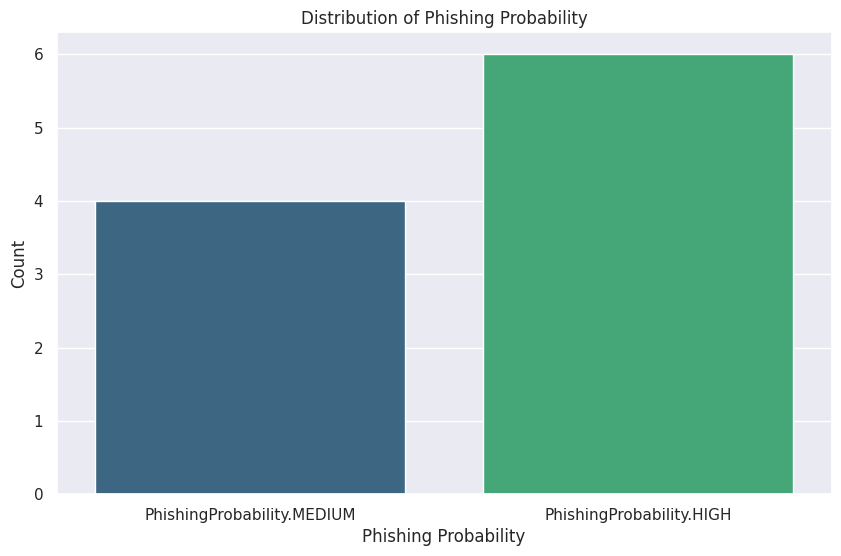

/tmp/ipykernel_7541/66192443.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_elements.values, y=top_elements.index, palette='mako')


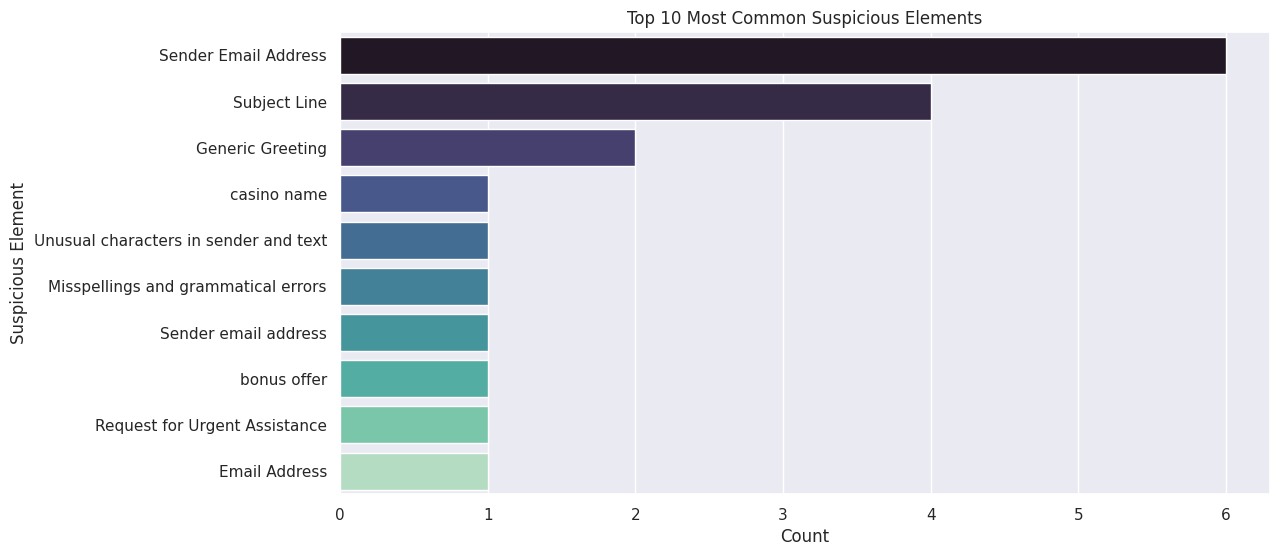

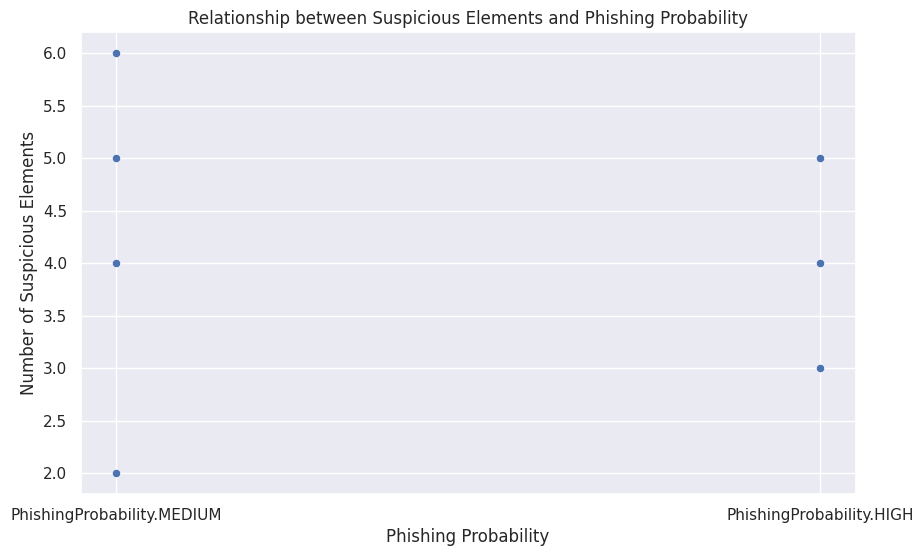

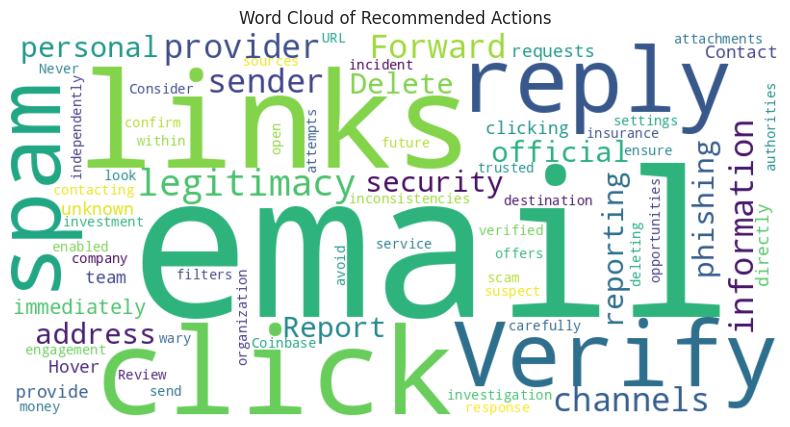


Detailed Information for High-Risk Emails:

Email 2:
Phishing Probability: PhishingProbability.HIGH
Suspicious Elements:
- Sender email address: The email address 'no-reply@nnymggojyxiotr' appears to be generic and not associated with a legitimate organization.
- Subject line: The subject line uses urgency and a tempting offer ('Fall 2026 Promo - $300 Off') to pressure the recipient into action. 
- Unusual characters in sender and text: The presence of unusual characters like 'üö®' and '‚úÖ' in the email text and sender name suggests potential spoofing.
- Misspellings and grammatical errors: The email contains minor misspellings and grammatical errors, which are common in phishing attempts to appear less professional.
Recommended Actions:
- Do not click on any links in the email.
- Do not reply to the email.
- Forward the email to your IT security team or spam reporting service.
- Verify the legitimacy of any offers or requests through official channels.
Explanation: Based on the sus

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display, HTML
from wordcloud import WordCloud

# Set style for better-looking plots
sns.set_theme()

print("Creating summary of results...")
df_results = pd.DataFrame([result.model_dump() for result in results])

# Display summary statistics
print("\nSummary of Analysis Results:")
print(f"Total emails analyzed: {len(df_results)}")
print(f"Potential phishing emails: {df_results['is_potential_phishing'].sum()}")
print(f"Percentage of potential phishing emails: {df_results['is_potential_phishing'].mean()*100:.2f}%")

# Visualize phishing probability distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='phishing_probability', data=df_results, hue='phishing_probability', legend=False, palette='viridis')
plt.title('Distribution of Phishing Probability')
plt.xlabel('Phishing Probability')
plt.ylabel('Count')
plt.show()

# Analyze and visualize suspicious elements
suspicious_elements = [element['element'] for sublist in df_results["suspicious_elements"] for element in sublist]
df_elements = pd.DataFrame({'element': suspicious_elements})

top_elements = df_elements["element"].value_counts().head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_elements.values, y=top_elements.index, palette='mako')
plt.title('Top 10 Most Common Suspicious Elements')
plt.xlabel('Count')
plt.ylabel('Suspicious Element')
plt.show()


# Correlation between suspicious elements and phishing probability
df_results['suspicious_element_count'] = df_results['suspicious_elements'].apply(len)

plt.figure(figsize=(10, 6))
sns.scatterplot(x='phishing_probability', y='suspicious_element_count', data=df_results)
plt.title('Relationship between Suspicious Elements and Phishing Probability')
plt.xlabel('Phishing Probability')
plt.ylabel('Number of Suspicious Elements')
plt.show()

# Word cloud of recommended actions
all_actions = ' '.join([' '.join(actions) for actions in df_results['recommended_actions']])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_actions)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Recommended Actions')
plt.show()

# Display detailed information for high-risk emails
high_risk_emails = df_results[df_results['phishing_probability'] == PhishingProbability.HIGH.value]
print("\nDetailed Information for High-Risk Emails:")
for idx, email in high_risk_emails.iterrows():
    print(f"\nEmail {idx+1}:")
    print(f"Phishing Probability: {email['phishing_probability']}")
    print("Suspicious Elements:")
    for element in email['suspicious_elements']:
        print(f"- {element['element']}: {element['reason']}")
    print("Recommended Actions:")
    for action in email['recommended_actions']:
        print(f"- {action}")
    print(f"Explanation: {email['explanation']}")
    print("-" * 50)

# Calculate and display overall risk score
risk_score_map = {PhishingProbability.LOW.value: 1, PhishingProbability.MEDIUM.value: 2, PhishingProbability.HIGH.value: 3}
df_results['risk_score'] = df_results['phishing_probability'].map(risk_score_map)
overall_risk_score = df_results['risk_score'].mean()

print(f"\nOverall Risk Score: {overall_risk_score:.2f} out of 3")

# Additional analysis
prob_counts = df_results['phishing_probability'].value_counts()
print("\nPhishing Probability Counts:")
print(prob_counts)

avg_suspicious = df_results['suspicious_element_count'].mean()
print(f"\nAverage number of suspicious elements per email: {avg_suspicious:.2f}")


all_actions = [action for actions in df_results['recommended_actions'] for action in actions]
action_counts = pd.Series(all_actions).value_counts()
print("\nTop 5 most common recommended actions:")
print(action_counts.head())

print("\nSample explanations:")
print(df_results['explanation'].sample(min(3, len(df_results))).to_string())

## Conclusion

This notebook demonstrates how to use LLMs for phishing email analysis. It covers setting up the environment, defining data models, implementing the analysis function, and creating a simple GUI for easy interaction. This approach can be extended and refined for more sophisticated email security applications.
